<a href="https://colab.research.google.com/github/miriamamin1213-ux/AUC_Curves/blob/main/HECKTORGPT2CNSHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# HECKTOR GPT-2 CLASSIFIER
# HPV Status Prediction | Compact Single-Cell Notebook
# ============================================================

# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
import os, random, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

SEED = 42
def seed_everything(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 2. LOAD HECKTOR EXCEL DATA
DATA_FILE = "HPV2025.xlsx"
if not os.path.exists(DATA_FILE):
    downloaded = gdown.download(
        id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
        output=DATA_FILE, quiet=False
    )
    if downloaded is None or not os.path.exists(DATA_FILE):
        raise FileNotFoundError("Could not download HPV2025.xlsx.")

df = pd.read_excel(DATA_FILE)
TARGET = "HPV Status"
FEATURES = [
    "Age", "Gender", "Tobacco Consumption", "Alcohol Consumption",
    "Performance Status", "T-stage", "N-stage", "M-stage"
]
missing = [c for c in [TARGET] + FEATURES if c not in df.columns]
if missing:
    raise KeyError(f"Required Excel columns missing: {missing}")

# 3. ROBUSTLY NORMALISE TARGET AND SELECT FEATURES
def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in {"0", "0.0", "negative", "neg", "false", "no"}:
        return 0
    if s in {"1", "1.0", "positive", "pos", "true", "yes"}:
        return 1
    try:
        n = float(s)
        if n in (0, 1):
            return int(n)
    except (ValueError, TypeError):
        pass
    return np.nan

df["HPV_Label"] = df[TARGET].apply(normalize_target)
invalid_count = int(df["HPV_Label"].isna().sum())
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
df = df[FEATURES + ["HPV_Label"]].copy()

if df.empty:
    raise ValueError("No recognised HPV labels found; check the target column.")
counts = df["HPV_Label"].value_counts().reindex([0, 1], fill_value=0)
if (counts < 2).any():
    raise ValueError(f"Insufficient examples for both HPV classes: {counts.to_dict()}")

print("Dataset:", df.shape, "| Invalid/missing target rows dropped:", invalid_count)
print("HPV classes (0=negative, 1=positive):\n", counts)

# 4. STRATIFIED TRAIN / VALIDATION / TEST SPLIT (65/15/20)
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)
train_df, val_df, test_df = [x.copy() for x in (train_df, val_df, test_df)]

# 5. IMPUTE MISSING FEATURES USING TRAINING DATA ONLY
fill_values = {}
for col in FEATURES:
    if pd.api.types.is_numeric_dtype(train_df[col]):
        value = train_df[col].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[col].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[col] = value
    for split in (train_df, val_df, test_df):
        split[col] = split[col].fillna(value)
        if split[col].dtype == object:
            split[col] = split[col].astype(str).replace(
                {"": "Unknown", "nan": "Unknown", "None": "Unknown"}
            )

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)
for name, y in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name}: n={len(y)}, class counts={np.bincount(y, minlength=2)}")


# 6. CONVERT THE EIGHT CLINICAL FEATURES INTO TEXT PROMPTS

def display_value(x):
    if pd.isna(x):
        return "Unknown"
    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))
    return str(x).strip()


def format_stage(x, prefix):
    value = display_value(x)

    if value == "Unknown" or value.upper().startswith(prefix):
        return value

    try:
        n = float(value)
        if n.is_integer():
            return f"{prefix}{int(n)}"
    except ValueError:
        pass

    return f"{prefix}{value}"


def patient_to_text(row):

    age = display_value(row["Age"])
    gender = display_value(row["Gender"])
    tobacco = display_value(row["Tobacco Consumption"])
    alcohol = display_value(row["Alcohol Consumption"])
    performance = display_value(row["Performance Status"])

    t_stage = format_stage(row["T-stage"], "T")
    n_stage = format_stage(row["N-stage"], "N")
    m_stage = format_stage(row["M-stage"], "M")

    return (
        f"This patient is a {age}-year-old {gender}. "
        f"Tobacco consumption is {tobacco}. "
        f"Alcohol consumption is {alcohol}. "
        f"Performance status is {performance}. "
        f"Tumour stage is {t_stage}. "
        f"Nodal stage is {n_stage}. "
        f"Metastatic stage is {m_stage}. "
        "Predict whether the patient is HPV positive or HPV negative."
    )


train_texts = [patient_to_text(r) for _, r in train_df.iterrows()]
val_texts = [patient_to_text(r) for _, r in val_df.iterrows()]
test_texts = [patient_to_text(r) for _, r in test_df.iterrows()]

# 7. LOAD TOKENIZER AND SET TRAINING PARAMETERS
MODEL_NAME = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token
lengths = [len(tokenizer.encode(t, add_special_tokens=False)) for t in train_texts]
MAX_LENGTH = min(1024, max(32, int(np.ceil(max(lengths) / 8) * 8)))
BATCH_SIZE, EPOCHS = 64, 500
LEARNING_RATE, WEIGHT_DECAY, DROPOUT = 1e-3, 1e-4, 0.1
print("Max prompt length:", max(lengths), "| MAX_LENGTH:", MAX_LENGTH)
print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS)

# 8. BUILD DATASETS AND DATA LOADERS
class HPVTextDataset(Dataset):
    def __init__(self, texts, labels):
        self.items = []
        for text, label in zip(texts, labels):
            enc = tokenizer(
                text, max_length=MAX_LENGTH, padding="max_length",
                truncation=True, return_tensors="pt"
            )
            self.items.append((
                enc["input_ids"].squeeze(0),
                enc["attention_mask"].squeeze(0), int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        ids, mask, label = self.items[i]
        return {"input_ids": ids, "attention_mask": mask,
                "label": torch.tensor(label, dtype=torch.long)}

train_ds = HPVTextDataset(train_texts, y_train)
val_ds = HPVTextDataset(val_texts, y_val)
test_ds = HPVTextDataset(test_texts, y_test)
loader_args = {
    "batch_size": BATCH_SIZE, "num_workers": 0,
    "pin_memory": torch.cuda.is_available()
}
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, shuffle=True, generator=generator, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)

# 9. INITIALISE GPT-2 CLASSIFIER AND CLASS-WEIGHTED LOSS
class HPVNetGPT2Text(nn.Module):
    def __init__(self):
        super().__init__()
        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)

        # Freeze the entire GPT-2 backbone
        for param in self.gpt2.parameters():
            param.requires_grad = False

        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id

        h = self.gpt2.config.hidden_size
        self.classifier = nn.Sequential(
            nn.LayerNorm(h),
            nn.Dropout(DROPOUT),
            nn.Linear(h, 128),
            nn.GELU(),
            nn.Dropout(DROPOUT),
            nn.Linear(128, 2)
        )

    def forward(self, input_ids, attention_mask):
        out = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False,
            return_dict=True
        ).last_hidden_state

        positions = attention_mask.sum(dim=1) - 1
        pooled = out[
            torch.arange(out.size(0), device=out.device),
            positions
        ]
        return self.classifier(pooled)


model = HPVNetGPT2Text().to(device)

class_counts = np.bincount(y_train, minlength=2)
class_weights = torch.tensor(
    len(y_train) / (2 * np.maximum(class_counts, 1)),
    dtype=torch.float32,
    device=device
)

def weighted_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits, labels, reduction="none"
    )
    return (losses * class_weights[labels]).mean()

# Train only the classification head
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

# 10. VALIDATION SCORING AND THRESHOLD SELECTION
def get_scores(loader):
    model.eval()
    scores, labels = [], []
    with torch.no_grad():
        for batch in loader:
            ids, mask = batch["input_ids"].to(device), batch["attention_mask"].to(device)
            logits = model(ids, mask)
            scores.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            labels.extend(batch["label"].numpy())
    return np.asarray(scores), np.asarray(labels, dtype=int)

def evaluate_loss(loader):
    model.eval()
    total, n_total = 0.0, 0
    with torch.no_grad():
        for b in loader:
            ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
            labels = b["label"].to(device)
            loss = weighted_loss(model(ids, mask), labels)
            n = len(labels); total += loss.item() * n; n_total += n
    return total / max(n_total, 1)

def choose_threshold(scores, labels):
    thresholds = np.unique(np.r_[0.0, scores, 1.0])
    values = [(float(t), balanced_accuracy_score(labels, scores >= t)) for t in thresholds]
    return max(values, key=lambda x: (x[1], -abs(x[0] - 0.5)))

# 11. TRAIN MODEL AND SAVE BEST VALIDATION CHECKPOINTS
from pathlib import Path

OUT_DIR = Path("/content/drive/MyDrive/HECKTOR_GPT2_Discriminative_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)
paths = {
    "Validation_Loss": OUT_DIR / "best_model_validation_loss.pth",
    "Validation_ROC_AUC": OUT_DIR / "best_model_validation_roc_auc.pth",
    "Validation_PR_AUC": OUT_DIR / "best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy": OUT_DIR / "best_model_validation_balanced_accuracy.pth"
}
best = {
    "Validation_Loss": float("inf"), "Validation_ROC_AUC": -float("inf"),
    "Validation_PR_AUC": -float("inf"), "Validation_Balanced_Accuracy": -float("inf")
}
best_info, history = {}, []

for epoch in range(1, EPOCHS + 1):
    model.train()
    model.gpt2.eval()
    loss_sum, n_sum = 0.0, 0
    for b in train_loader:
        ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
        labels = b["label"].to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = weighted_loss(model(ids, mask), labels)
        loss.backward()
        optimizer.step()
        n = len(labels); loss_sum += loss.item() * n; n_sum += n

    train_loss = loss_sum / max(n_sum, 1)
    val_loss = evaluate_loss(val_loader)
    val_scores, val_labels = get_scores(val_loader)
    val_auc = roc_auc_score(val_labels, val_scores)
    val_ap = average_precision_score(val_labels, val_scores)
    threshold, val_ba = choose_threshold(val_scores, val_labels)
    metrics = {
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap, "Validation_Balanced_Accuracy": val_ba
    }
    history.append({
        "Epoch": epoch, "Train_Loss": train_loss, **metrics,
        "Validation_Threshold": threshold
    })

    for name, value in metrics.items():
        improved = value < best[name] if name == "Validation_Loss" else value > best[name]
        if improved:
            best[name] = float(value)
            best_info[name] = {"epoch": epoch, "value": float(value), "threshold": threshold}
            torch.save(model.state_dict(), paths[name])

    if epoch % 50 == 0:
        print(f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
              f"Val Loss={val_loss:.4f} | ROC-AUC={val_auc:.4f} | "
              f"PR-AUC={val_ap:.4f} | BA={val_ba:.4f} | Threshold={threshold:.4f}")

pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)
pd.DataFrame([
    {"Checkpoint": k, **v, "Path": str(paths[k])} for k, v in best_info.items()
]).to_csv(OUT_DIR / "best_validation_checkpoints.csv", index=False)

# 12. EVALUATE ALL CHECKPOINTS ON HELD-OUT TEST SET
results, predictions_by_model = [], {}
for name, path in paths.items():
    model.load_state_dict(torch.load(path, map_location=device))
    scores, labels = get_scores(test_loader)
    threshold = best_info[name]["threshold"]
    preds = (scores >= threshold).astype(int)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)
    ba = balanced_accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, zero_division=0)
    cm = confusion_matrix(labels, preds, labels=[0, 1])

    print(f"\n=== {name} | Best epoch {best_info[name]['epoch']} | Threshold {threshold:.4f} ===")
    print(classification_report(
        labels, preds, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"], digits=4, zero_division=0
    ))
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)
    print(f"Test ROC-AUC={auc:.4f} | PR-AUC={ap:.4f} | BA={ba:.4f} | F1={f1:.4f}")

    results.append({
        "Dataset": "HECKTOR", "Model": "GPT-2 Classifier",
        "Checkpoint_Selected_By": name, "Best_Epoch": best_info[name]["epoch"],
        "Validation_Threshold": threshold, "Test_ROC_AUC": auc,
        "Test_PR_AUC": ap, "Test_Balanced_Accuracy": ba, "Test_F1": f1,
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1]
    })
    predictions_by_model[name] = (labels, scores, preds, threshold)
    pd.DataFrame({
        "True_Label": labels, "HPV_Positive_Score": scores,
        "Predicted_Label": preds, "Threshold": threshold
    }).to_csv(OUT_DIR / f"test_predictions_{name.lower()}.csv", index=False)

results_df = pd.DataFrame(results)
results_df.to_csv(OUT_DIR / "test_metrics_by_checkpoint.csv", index=False)

# 13. SAVE ROC AND PRECISION-RECALL CURVES
for name, (labels, scores, preds, threshold) in predictions_by_model.items():
    safe = name.lower()
    fpr, tpr, roc_thresholds = roc_curve(labels, scores)
    precision, recall, _ = precision_recall_curve(labels, scores)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)

    pd.DataFrame({"FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds}).to_csv(
        OUT_DIR / f"roc_coordinates_{safe}.csv", index=False
    )
    pd.DataFrame({"Precision": precision, "Recall": recall}).to_csv(
        OUT_DIR / f"pr_coordinates_{safe}.csv", index=False
    )

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"HECKTOR ROC — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"roc_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

    plt.figure(figsize=(6, 5))
    plt.plot(recall, precision, label=f"AP={ap:.3f}")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(f"HECKTOR Precision-Recall — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"pr_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

# 14. SAVE SETTINGS AND COMPARISON RESULTS
settings = {
    "Dataset": "HECKTOR", "Model": MODEL_NAME, "Target": "HPV Status",
    "Features": ", ".join(FEATURES), "Number_of_Features": len(FEATURES),
    "Split": "65/15/20 stratified", "Seed": SEED, "Epochs": EPOCHS,
    "Batch_Size": BATCH_SIZE, "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY, "Dropout": DROPOUT,
    "Max_Length": MAX_LENGTH, "Optimizer": "AdamW",
    "Class_Weighted_Loss": True, "GPT2_Backbone_Frozen": True,
    "Checkpoint_Selection": "Validation loss, ROC-AUC, PR-AUC, balanced accuracy",
    "Threshold_Selection": "Maximum validation balanced accuracy"
}
pd.DataFrame([settings]).to_csv(OUT_DIR / "settings.csv", index=False)

comparison_file = Path("model_roc_pr_auc_comparison.csv")
comparison = results_df[[
    "Dataset", "Model", "Checkpoint_Selected_By", "Best_Epoch",
    "Test_ROC_AUC", "Test_PR_AUC", "Test_Balanced_Accuracy", "Test_F1"
]]
if comparison_file.exists():
    old = pd.read_csv(comparison_file)
    combined = pd.concat([old, comparison], ignore_index=True, sort=False)
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"], keep="last"
    )
else:
    combined = comparison
combined.to_csv(comparison_file, index=False)

print("\nAll outputs saved to:", OUT_DIR.resolve())
print("Comparison CSV:", comparison_file.resolve())

Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 1.20MB/s]


Dataset: (588, 9) | Invalid/missing target rows dropped: 138
HPV classes (0=negative, 1=positive):
 HPV_Label
0     58
1    530
Name: count, dtype: int64
Train: n=381, class counts=[ 37 344]
Validation: n=89, class counts=[ 9 80]
Test: n=118, class counts=[ 12 106]


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Trainable parameters: 100226
Trainable parameters: 100226
Epoch 50/500 | Train Loss=0.6867 | Val Loss=0.6946 | ROC-AUC=0.8042 | PR-AUC=0.9727 | BA=0.7701 | Threshold=0.5226
Epoch 100/500 | Train Loss=0.6427 | Val Loss=0.6593 | ROC-AUC=0.8014 | PR-AUC=0.9720 | BA=0.7764 | Threshold=0.4679
Epoch 150/500 | Train Loss=0.6230 | Val Loss=0.6117 | ROC-AUC=0.7944 | PR-AUC=0.9701 | BA=0.7764 | Threshold=0.4975
Epoch 200/500 | Train Loss=0.5623 | Val Loss=0.5856 | ROC-AUC=0.8014 | PR-AUC=0.9726 | BA=0.7701 | Threshold=0.4964
Epoch 250/500 | Train Loss=0.6731 | Val Loss=0.5929 | ROC-AUC=0.7847 | PR-AUC=0.9703 | BA=0.7889 | Threshold=0.3629
Epoch 300/500 | Train Loss=0.5354 | Val Loss=0.5833 | ROC-AUC=0.7833 | PR-AUC=0.9703 | BA=0.7889 | Threshold=0.5110
Epoch 350/500 | Train Loss=0.5514 | Val Loss=0.6007 | ROC-AUC=0.7764 | PR-AUC=0.9690 | BA=0.7764 | Threshold=0.5563
Epoch 400/500 | Train Loss=0.5388 | Val Loss=0.5799 | ROC-AUC=0.7764 | PR-AUC=0.9692 | BA=0.7701 | Threshold=0.4261
Epoch 450/500 |

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Loaded best validation ROC-AUC checkpoint.
Original features: ['Age', 'Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']
Training explanation matrix: (381, 8)
Test explanation matrix: (118, 8)

Selected patients:
HPV-positive test index: 0
HPV-negative test index: 6

SHAP background samples: 20

EXPLAINING: HPV_positive
Actual class: 1
Predicted class: 1
HPV-negative probability: 0.0038
HPV-positive probability: 0.9962

Calculating SHAP values...


  0%|          | 0/1 [00:00<?, ?it/s]

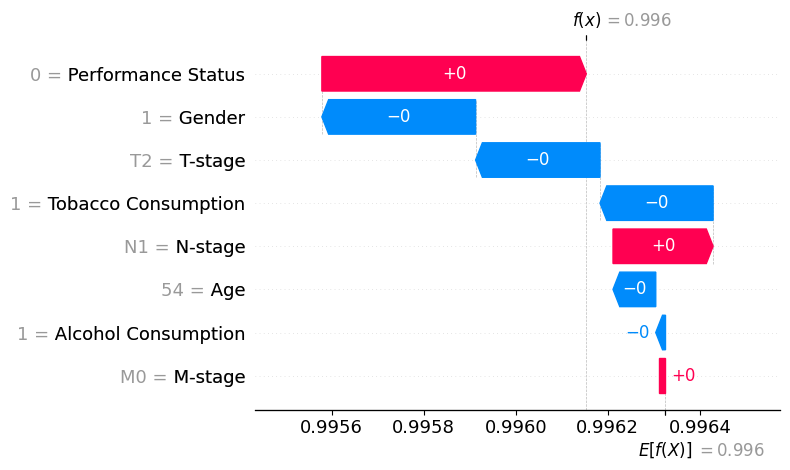

Saved: HPV_positive_SHAP_waterfall.png

Calculating LIME values...


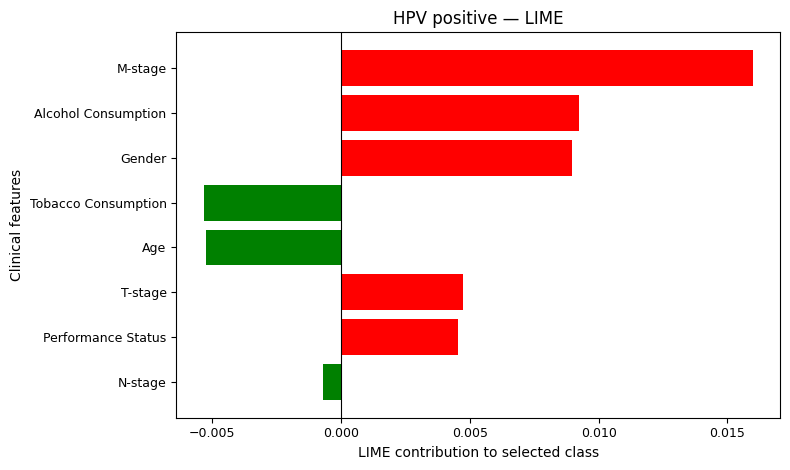

Saved: HPV_positive_LIME_bar.png

EXPLAINING: HPV_negative
Actual class: 0
Predicted class: 1
HPV-negative probability: 0.0044
HPV-positive probability: 0.9956

Calculating SHAP values...


  0%|          | 0/1 [00:00<?, ?it/s]

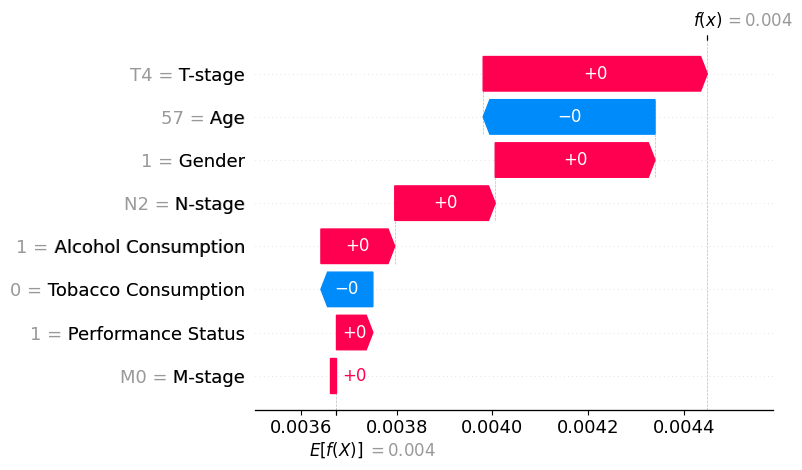

Saved: HPV_negative_SHAP_waterfall.png

Calculating LIME values...


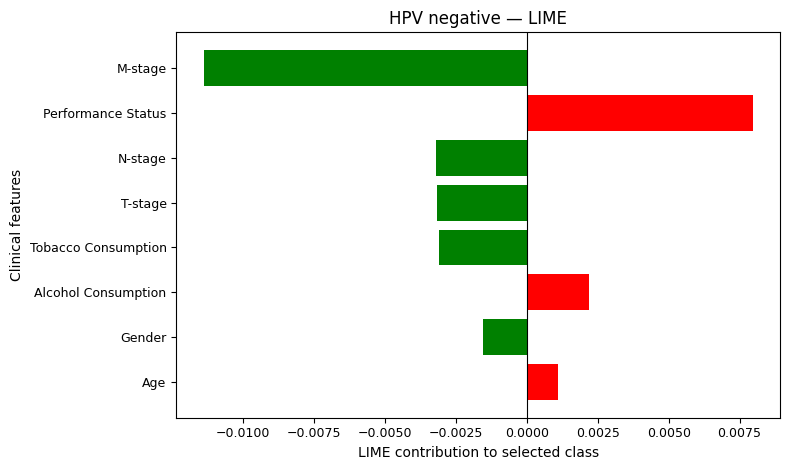

Saved: HPV_negative_LIME_bar.png

Patient prediction summary:


,Patient,Actual_Class,Predicted_Class,HPV_Negative_Probability,HPV_Positive_Probability
0,HPV_positive,1,1,0.003847,0.996153
1,HPV_negative,0,1,0.004448,0.995552



IMAGE DIMENSION CHECK
HPV_positive_SHAP_waterfall.png : (2400, 1440) pixels
HPV_positive_LIME_bar.png : (2400, 1440) pixels
HPV_negative_SHAP_waterfall.png : (2400, 1440) pixels
HPV_negative_LIME_bar.png : (2400, 1440) pixels

All four plots saved to:
/content/drive/MyDrive/HECKTOR_GPT2_Discriminative_results/SHAP_LIME_Individual_Patients



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Finished!


In [2]:

# ============================================================
# HECKTOR GPT-2 TEXT CLASSIFIER
# SHAP + LIME: ONE ACTUAL HPV-POSITIVE AND ONE ACTUAL NEGATIVE
# Four same-size PNG plots + ZIP download
# ============================================================

!pip -q install shap lime

import os
import zipfile
import numpy as np
import pandas as pd
import torch
import shap
import matplotlib.pyplot as plt

from pathlib import Path
from lime.lime_tabular import LimeTabularExplainer
from google.colab import files
from PIL import Image

# ------------------------------------------------------------
# 1. CHECK REQUIRED NOTEBOOK VARIABLES
# ------------------------------------------------------------

required = [
    "model", "device", "tokenizer", "MAX_LENGTH",
    "train_df", "test_df", "y_train", "y_test",
    "patient_to_text", "OUT_DIR", "FEATURES"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise NameError(
        "Please run the notebook's data preparation and model "
        f"sections first. Missing variables: {missing}"
    )

# Use the exact eight original clinical predictors.
FEATURES = [
    "Age",
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

# ------------------------------------------------------------
# 2. LOAD BEST VALIDATION ROC-AUC CHECKPOINT
# ------------------------------------------------------------

checkpoint_path = Path(OUT_DIR) / "best_model_validation_roc_auc.pth"

if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_path}\n"
        "Run the training section of your notebook first."
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# This notebook saves the raw model state dictionary.
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]

model.load_state_dict(checkpoint)
model.to(device)
model.eval()

print("Loaded best validation ROC-AUC checkpoint.")

# ------------------------------------------------------------
# 3. PREPARE ORIGINAL CLINICAL FEATURES
# ------------------------------------------------------------

categorical_features = [
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

# Use training data to define category mappings.
# The original clinical values are retained for display.
category_maps = {}
category_names = {}

for col in categorical_features:

    categories = sorted(
        train_df[col].fillna("Unknown").astype(str).unique().tolist()
    )

    if "Unknown" not in categories:
        categories.append("Unknown")

    category_maps[col] = {
        value: i for i, value in enumerate(categories)
    }

    category_names[col] = categories


# Fill missing age using the training median.
age_median = pd.to_numeric(
    train_df["Age"], errors="coerce"
).median()

if pd.isna(age_median):
    age_median = 0.0


def prepare_original_dataframe(dataframe):

    result = dataframe[FEATURES].copy()

    result["Age"] = pd.to_numeric(
        result["Age"], errors="coerce"
    ).fillna(age_median)

    for col in categorical_features:

        result[col] = (
            result[col]
            .fillna("Unknown")
            .astype(str)
            .replace({
                "": "Unknown",
                "nan": "Unknown",
                "None": "Unknown"
            })
        )

        result[col] = result[col].apply(
            lambda value: (
                value if value in category_maps[col]
                else "Unknown"
            )
        )

    return result


train_original = prepare_original_dataframe(train_df)
test_original = prepare_original_dataframe(test_df)


# ------------------------------------------------------------
# 4. ENCODE THE EIGHT ORIGINAL FEATURES FOR SHAP AND LIME
# ------------------------------------------------------------

def dataframe_to_matrix(dataframe):

    matrix = np.zeros(
        (len(dataframe), len(FEATURES)),
        dtype=np.float64
    )

    matrix[:, 0] = pd.to_numeric(
        dataframe["Age"], errors="coerce"
    ).fillna(age_median).to_numpy(dtype=float)

    for j, col in enumerate(categorical_features, start=1):

        mapping = category_maps[col]

        matrix[:, j] = dataframe[col].map(
            mapping
        ).fillna(mapping["Unknown"]).to_numpy(dtype=float)

    return matrix


X_explain_train = dataframe_to_matrix(train_original)
X_explain_test = dataframe_to_matrix(test_original)

# LIME categorical feature indices.
categorical_indices = list(range(1, len(FEATURES)))

# LIME categorical names.
lime_categorical_names = {
    j: category_names[col]
    for j, col in enumerate(categorical_features, start=1)
}

print("Original features:", FEATURES)
print("Training explanation matrix:", X_explain_train.shape)
print("Test explanation matrix:", X_explain_test.shape)


# ------------------------------------------------------------
# 5. DECODE PERTURBED FEATURES INTO ORIGINAL CLINICAL ROWS
# ------------------------------------------------------------

def matrix_to_dataframe(data):

    data = np.asarray(data, dtype=float)

    if data.ndim == 1:
        data = data.reshape(1, -1)

    rows = []

    for row in data:

        patient = {}

        patient["Age"] = float(row[0])

        for j, col in enumerate(categorical_features, start=1):

            categories = category_names[col]

            category_index = int(
                np.clip(
                    np.rint(row[j]),
                    0,
                    len(categories) - 1
                )
            )

            patient[col] = categories[category_index]

        rows.append(patient)

    return pd.DataFrame(rows, columns=FEATURES)


def matrix_to_texts(data):

    dataframe = matrix_to_dataframe(data)

    return [
        patient_to_text(row)
        for _, row in dataframe.iterrows()
    ]


# ------------------------------------------------------------
# 6. GPT-2 PREDICTION FUNCTION FOR SHAP AND LIME
# ------------------------------------------------------------

def gpt2_predict_proba(data):

    data = np.asarray(data, dtype=float)

    if data.ndim == 1:
        data = data.reshape(1, -1)

    if data.shape[1] != len(FEATURES):
        raise ValueError(
            f"Expected {len(FEATURES)} features, "
            f"received {data.shape[1]}."
        )

    texts = matrix_to_texts(data)

    all_probabilities = []

    model.eval()

    with torch.no_grad():

        for start in range(0, len(texts), 16):

            batch_texts = texts[start:start + 16]

            encoded = tokenizer(
                batch_texts,
                max_length=MAX_LENGTH,
                padding="max_length",
                truncation=True,
                return_tensors="pt"
            )

            input_ids = encoded["input_ids"].to(device)
            attention_mask = encoded["attention_mask"].to(device)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            all_probabilities.append(
                probabilities.cpu().numpy()
            )

    return np.vstack(all_probabilities)


# ------------------------------------------------------------
# 7. SELECT ONE ACTUAL HPV-POSITIVE AND ONE ACTUAL HPV-NEGATIVE
# ------------------------------------------------------------

y_test_array = np.asarray(y_test).astype(int)

positive_indices = np.where(y_test_array == 1)[0]
negative_indices = np.where(y_test_array == 0)[0]

if len(positive_indices) == 0:
    raise ValueError("No actual HPV-positive patient in test set.")

if len(negative_indices) == 0:
    raise ValueError("No actual HPV-negative patient in test set.")

# Select the first actual patient from each class.
positive_idx = int(positive_indices[0])
negative_idx = int(negative_indices[0])

print("\nSelected patients:")
print("HPV-positive test index:", positive_idx)
print("HPV-negative test index:", negative_idx)

# ------------------------------------------------------------
# 8. CREATE OUTPUT DIRECTORY
# ------------------------------------------------------------

output_dir = Path(OUT_DIR) / "SHAP_LIME_Individual_Patients"
output_dir.mkdir(parents=True, exist_ok=True)

# Identical dimensions and resolution for all four plots.
FIGSIZE = (8, 4.8)
DPI = 300


# ------------------------------------------------------------
# 9. SHAP BACKGROUND DATA AND LIME EXPLAINER
# ------------------------------------------------------------

rng = np.random.default_rng(42)

background_size = min(20, len(X_explain_train))

background_indices = rng.choice(
    len(X_explain_train),
    size=background_size,
    replace=False
)

background = X_explain_train[background_indices]

print("\nSHAP background samples:", background_size)

lime_explainer = LimeTabularExplainer(
    training_data=X_explain_train,
    feature_names=FEATURES,
    categorical_features=categorical_indices,
    categorical_names=lime_categorical_names,
    class_names=["HPV Negative", "HPV Positive"],
    mode="classification",
    discretize_continuous=False,
    random_state=42
)


# ------------------------------------------------------------
# 10. FUNCTION TO EXPLAIN ONE PATIENT
# ------------------------------------------------------------

def explain_patient(patient_name, patient_index, actual_class):

    print("\n" + "=" * 60)
    print("EXPLAINING:", patient_name)
    print("=" * 60)

    patient = X_explain_test[
        patient_index:patient_index + 1
    ]

    probabilities = gpt2_predict_proba(patient)[0]

    predicted_class = int(np.argmax(probabilities))

    print("Actual class:", actual_class)
    print("Predicted class:", predicted_class)
    print("HPV-negative probability:", round(float(probabilities[0]), 4))
    print("HPV-positive probability:", round(float(probabilities[1]), 4))

    if int(y_test_array[patient_index]) != actual_class:
        raise ValueError("Selected patient has an unexpected actual label.")

    # --------------------------------------------------------
    # SHAP WATERFALL
    # --------------------------------------------------------

    print("\nCalculating SHAP values...")

    def predict_selected_class(data):
        return gpt2_predict_proba(data)[:, actual_class]

    shap_explainer = shap.KernelExplainer(
        predict_selected_class,
        background
    )

    shap_result = shap_explainer.shap_values(
        patient,
        nsamples=300
    )

    if isinstance(shap_result, list):

        shap_values = np.asarray(
            shap_result[0]
        ).reshape(-1)

    else:

        shap_values = np.asarray(shap_result)

        if shap_values.ndim == 3:
            shap_values = shap_values[0, :, 0]

        elif shap_values.ndim == 2:
            shap_values = shap_values[0]

        shap_values = shap_values.reshape(-1)

    expected_value = shap_explainer.expected_value

    expected_value = float(
        np.asarray(expected_value).reshape(-1)[0]
    )

    # Actual original clinical values for the selected patient.
    display_row = test_df.iloc[patient_index]

    display_values = []

    for col in FEATURES:

        value = display_row[col]

        if pd.isna(value):
            value = "Unknown"

        display_values.append(value)

    shap_explanation = shap.Explanation(
        values=shap_values,
        base_values=expected_value,
        data=np.asarray(display_values, dtype=object),
        feature_names=FEATURES
    )

    shap_filename = f"{patient_name}_SHAP_waterfall.png"

    plt.figure(figsize=FIGSIZE)

    shap.plots.waterfall(
        shap_explanation,
        max_display=len(FEATURES),
        show=False
    )

    plt.gcf().set_size_inches(*FIGSIZE)
    plt.tight_layout()

    plt.savefig(
        output_dir / shap_filename,
        dpi=DPI,
        format="png"
    )

    plt.show()
    plt.close("all")

    print("Saved:", shap_filename)

    # --------------------------------------------------------
    # LIME BAR CHART
    # --------------------------------------------------------

    print("\nCalculating LIME values...")

    lime_explanation = lime_explainer.explain_instance(
        data_row=patient[0],
        predict_fn=gpt2_predict_proba,
        labels=(actual_class,),
        num_features=len(FEATURES),
        num_samples=1500
    )

    lime_weights = np.zeros(
        len(FEATURES),
        dtype=float
    )

    for feature_index, contribution in lime_explanation.as_map()[
        actual_class
    ]:

        lime_weights[feature_index] = contribution

    # Sort features by absolute contribution.
    order = np.argsort(np.abs(lime_weights))

    sorted_features = [
        FEATURES[i] for i in order
    ]

    sorted_weights = lime_weights[order]

    # Red = toward the selected class.
    # Green = away from the selected class.
    bar_colours = [
        "red" if value > 0 else "green"
        for value in sorted_weights
    ]

    lime_filename = f"{patient_name}_LIME_bar.png"

    plt.figure(figsize=FIGSIZE)

    plt.barh(
        sorted_features,
        sorted_weights,
        color=bar_colours
    )

    plt.axvline(
        0,
        color="black",
        linewidth=0.8
    )

    plt.xlabel("LIME contribution to selected class")
    plt.ylabel("Clinical features")

    plt.title(
        f"{patient_name.replace('_', ' ')} — LIME"
    )

    plt.xticks(fontsize=9)
    plt.yticks(fontsize=9)

    plt.gcf().set_size_inches(*FIGSIZE)
    plt.tight_layout()

    plt.savefig(
        output_dir / lime_filename,
        dpi=DPI,
        format="png"
    )

    plt.show()
    plt.close("all")

    print("Saved:", lime_filename)

    return {
        "Patient": patient_name,
        "Actual_Class": actual_class,
        "Predicted_Class": predicted_class,
        "HPV_Negative_Probability": float(probabilities[0]),
        "HPV_Positive_Probability": float(probabilities[1])
    }


# ------------------------------------------------------------
# 11. GENERATE THE FOUR PLOTS
# ------------------------------------------------------------

positive_summary = explain_patient(
    patient_name="HPV_positive",
    patient_index=positive_idx,
    actual_class=1
)

negative_summary = explain_patient(
    patient_name="HPV_negative",
    patient_index=negative_idx,
    actual_class=0
)


# ------------------------------------------------------------
# 12. SAVE PATIENT SUMMARY
# ------------------------------------------------------------

summary_df = pd.DataFrame([
    positive_summary,
    negative_summary
])

summary_path = output_dir / "patient_prediction_summary.csv"

summary_df.to_csv(
    summary_path,
    index=False
)

print("\nPatient prediction summary:")
display(summary_df)


# ------------------------------------------------------------
# 13. CREATE ZIP FILE
# ------------------------------------------------------------

plot_files = [
    output_dir / "HPV_positive_SHAP_waterfall.png",
    output_dir / "HPV_positive_LIME_bar.png",
    output_dir / "HPV_negative_SHAP_waterfall.png",
    output_dir / "HPV_negative_LIME_bar.png"
]

zip_path = output_dir / "HECKTOR_GPT2_SHAP_LIME_ALL_4_PLOTS.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for file_path in plot_files:

        if not file_path.exists():
            raise FileNotFoundError(
                f"Plot was not created: {file_path}"
            )

        zipf.write(
            file_path,
            arcname=file_path.name
        )


# ------------------------------------------------------------
# 14. VERIFY ALL FOUR IMAGE DIMENSIONS
# ------------------------------------------------------------

print("\nIMAGE DIMENSION CHECK")

for file_path in plot_files:

    with Image.open(file_path) as img:

        print(
            file_path.name,
            ":", img.size,
            "pixels"
        )


# ------------------------------------------------------------
# 15. DOWNLOAD ZIP AUTOMATICALLY
# ------------------------------------------------------------

print("\nAll four plots saved to:")
print(output_dir)

print("\nDownloading ZIP file...")

files.download(str(zip_path))

print("\nFinished!")
